In [1]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

#  Copyright (c) 2021 - 2022.  FlexibleLecture@Linkedin
#  All rights reserved.

# Created By  : FlexibleLecture@Linkedin
# Created Date: 5/7/2022
# version ='1.0'

### Demo: The influence to the convergence rate for different $\alpha, \beta$ for the gradient method applied to log barrier function

In the text book {book-convex-2004}, section 9.3, gradient descent method, the author has discussed the convergence of the gradient method for a problem in the form of  
$$
\min f(x)=c^T x -\displaystyle{\sum_{i=1}^{m}}\log(b_i-a_i^Tx)
$$
for m=500 and n=100, $x\in R^n$. 

In the demo, the number of iterations required
to obtain $f(x)-p^*<1e-5$ are determined by examining the backtracking line search under different values of the parameters $\alpha, \beta$. 

More details on the setup of the demo in Jupiter notebook for practice can be accessed from the Lecture's JupyterLab webpage:

[JupyterLab webpage](https://wuzhuchun.club:9091/lab/tree/welcome.ipynb}{https://wuzhuchun.club:9091/lab/tree/welcome.ipynb).


In [2]:
import numpy as np
import matplotlib.pyplot as plt

The log barrier function $f(x)=c^T \Gamma x -\displaystyle{\sum_{i=1}^{m}}\log(b_i-a_i^T\Gamma x)$

The derivative of the log barrier function, $\nabla f(x)=\Gamma^T c+\Gamma^T \displaystyle{\sum_{i=1}^{m}}\dfrac{A^T}{b_i-a_i^T\Gamma x}$

x should satisfy that: $b-A\Gamma x\succeq 0$

In [3]:
def my_f_fesasible(x, c, b, A, G):
    """
    x should satisfy that: $b-A\Gamma x\succeq 0$
    :param x:
    :param c:
    :param b:
    :param A:
    :return:
    """
    return np.all(b - A @ (G @ x) > 0)


def my_f(x, c, b, A, G):
    """
    the log barrier function $f(x)=c^T \Gamma x -\displaystyle{\sum_{i=1}^{m}}\log(b_i-a_i^T\Gamma x)$
    :param x:
    :param c:
    :param b:
    :param A:
    :return:
    """
    return (c.T @ (G @ x) - np.sum(np.log(b - A @ (G @ x)))).item()


def my_derivative_f(x, c, b, A, G):
    """
    the derivative of the log barrier function, $\nabla f(x)=\Gamma^T c+\Gamma^T \displaystyle{\sum_{i=1}^{m}}\dfrac{A^T}{b_i-a_i^T\Gamma x}$
    :param x:
    :param c:
    :param b:
    :param A:
    :return:
    """
    return (G.T @ c) + G.T @ (np.sum((A.T) @ (1/(b-A @ (G @ x))), axis=1).reshape((-1, 1)))

The backtracking line search method

In [4]:
def backtracking_line_search(t0, f, df, x, delta_x, alpha, beta, args):
    """
    the backtracking line search method
    :param t0:
    :param f:
    :param df:
    :param x:
    :param delta_x:
    :param alpha:
    :param beta:
    :param args:
    :return:
    """
    t = t0
    while (not my_f_fesasible(x + delta_x * t, *args)) or f(x + delta_x * t, *args) > f(x, *args) + alpha * t * (
            df(x, *args).T @ delta_x).item():
        t = beta * t
    return t

In [5]:
def plot_condition_number(gammas, ax, m, n):
    np.random.seed(1)
    A = np.random.rand(m, n)
    if not np.linalg.matrix_rank(A) == n:
        raise RuntimeError("rank(A) should be equal to n!")

    Lambda = -1 * np.random.rand(m, 1)
    c = A.T @ Lambda
    inv_Lambda = 1 / Lambda
    b = -1 * inv_Lambda
    f_min = -np.sum(np.log(b)).item()
    args = (c, b, A)

    conds = []
    for gamma in gammas:
        Gamma = np.diag(np.array([gamma ** (k/n) for k in range(n)]))
        nablaF = Gamma @ A.T * np.diag(b ** 2) @ A @ Gamma
        cond = np.linalg.cond(nablaF)
        conds.append(cond)
        #print(r'$\gamma$ = {}, cond={}'.format(gamma, cond))

    ax.loglog(gammas, conds, marker='+', fillstyle='none')
    ax.set_xlabel(r'$\gamma$')
    ax.set_ylabel(r'$\kappa(\nabla F(x^*))$')
    ax.grid()

In [6]:
def plot_log_barrier_convergence_vs_condition_number(gammas, ax, m=10, n=2, max_num_iter=2000, num_sim_per_alpha=10):
    """
    plot the convergence of the x during the gradient method vs. condition number
    :return:
    """
    n_iters = []
    for gamma in gammas:
        n_iters_per_sim = []
        #print('Info: running simulation for gamma = {}'.format(gamma))
        for sim in range(num_sim_per_alpha):
            np.random.seed(sim)
            epsilon = 1e-5
            A = np.random.rand(m, n)

            if not np.linalg.matrix_rank(A) == n:
                raise RuntimeError("rank(A) should be equal to n!")

            Lambda = -1 * np.random.rand(m, 1)
            c = A.T @ Lambda
            inv_Lambda = 1 / Lambda
            b = -1 * inv_Lambda

            f_min = -np.sum(np.log(b)).item()
            Gamma = np.diag(np.array([gamma ** (k / n) for k in range(n)]))

            args = (c, b, A, Gamma)

            alpha = 0.1
            beta = 0.5
            x0 = -1 * np.linalg.inv(Gamma) @ np.ones([n, 1])
            x = x0
            delta_x = -1 * my_derivative_f(x0, *args)
            x_points = np.zeros([max_num_iter, n])
            fx = np.zeros([max_num_iter, 1])
            t0 = 1

            for iter in range(max_num_iter):
                x_points[iter] = np.squeeze(x)
                fx[iter] = my_f(x, *args)

                if fx[iter] - f_min <= epsilon:
                    break

                t = backtracking_line_search(t0, my_f, my_derivative_f, x, delta_x, alpha, beta, args)
                x_next = x + t * delta_x

                x = x_next
                delta_x = -1 * my_derivative_f(x_next, *args)
            #print('Info: gamma = {}, sim = {}, iter={}'.format(gamma, sim, iter))
            n_iters_per_sim.append(iter)

        n_iters.append(np.average(np.array([n_iters_per_sim])))

    ax.loglog(gammas, n_iters, marker='+', fillstyle='none', label=r'number of iteration vs $\gamma$')
    ax.set_xlabel(r'$\gamma$')
    ax.set_ylabel(r'num of iterations')
    ax.grid()
    ax.legend()

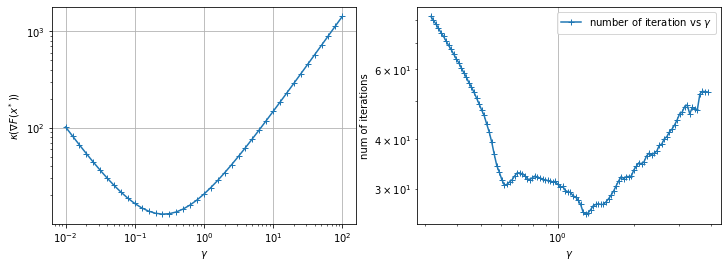

In [7]:
if __name__ == "__main__":
    plt.figure(figsize=(12, 4))
    ax = plt.subplot(1, 2, 1)
    gammas = 10 ** np.arange(-2, 2 + 0.1, 0.1)
    plot_condition_number(gammas=gammas, ax=ax, m=10, n=2)

    ax = plt.subplot(1, 2, 2)
    gammas = 10 ** np.arange(-0.5, 0.5 + 0.1, 0.01)
    plot_log_barrier_convergence_vs_condition_number(gammas=gammas, ax=ax, m=10, n=2)
    plt.show()